# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [56]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [57]:

%matplotlib inline
sys.path.append("..")

import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [455]:
# Set sampling rate and noise std
sampling_rate = 50e6
std_noise = 0.1

# Bubble dynamcis parameters
R_init = 4e-6
frequency = 7e5
pac = -10e4

# Parameters for FFT plot
fft_lim = 10 * frequency

# Parameters for the wavelet transform
wavelet = "db4"
levels = 6
mode = "symmetric"

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [456]:
# generate sound wave
data, t_plot = train.get_data(R_init, frequency, pac, sampling_rate, return_time=True)
data = (data - np.average(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
signal_length = len(data)

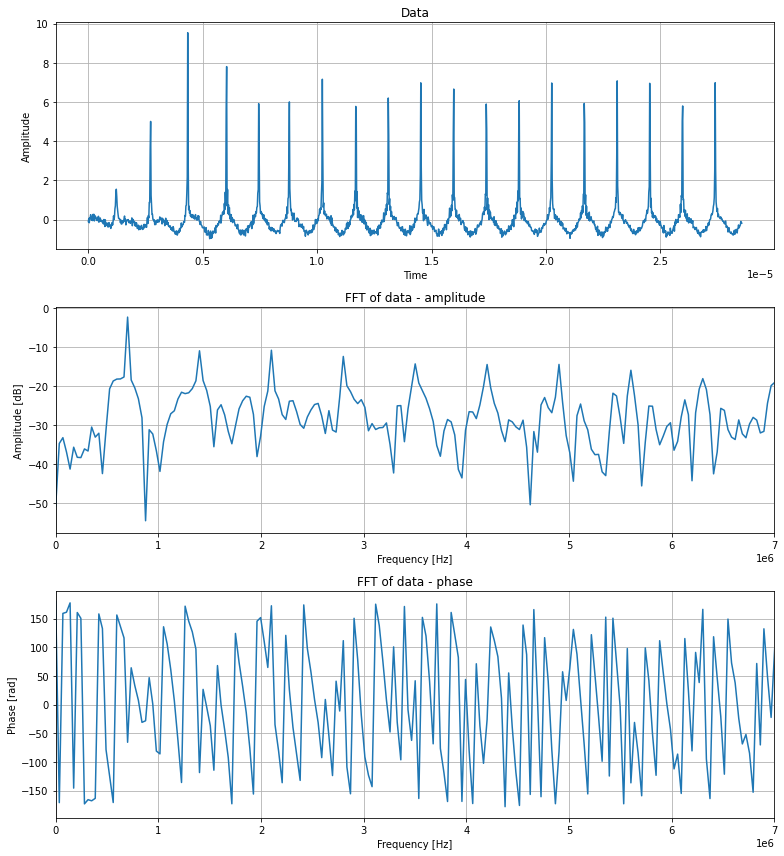

In [457]:
# Plot generated data
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    20*np.log10(np.abs(fft_data))
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

Wavelet transform

In [458]:
wpt_df, tr_ob = train.generate_training_data(
    data, levels, wavelet, mode, 
    include_tr_ob=True, min_entropy=False
)

In [459]:
wpt_df.head()

,level,node number,frequency range,centre frequency,energy,log energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,6,0,"(0, 1.562e-2)",0.007812,18.016924,1.255681,11.855995,1.095504,-2.931017,2.931017,1.192513,4.595790,0.069323
1,6,1,"(1.562e-2, 3.125e-2)",0.023438,356.650649,2.552243,2.282613,2.006340,0.111447,0.111447,2.728864,2.785168,1.015955
2,6,3,"(3.125e-2, 4.688e-2)",0.039062,231.724992,2.364973,2.189271,1.746473,-0.212457,0.212457,2.781046,2.874973,0.737318
3,6,2,"(4.688e-2, 6.25e-2)",0.054688,109.556468,2.039638,2.072370,1.766536,-0.166071,0.166071,2.875517,3.807433,0.412313
4,6,6,"(6.25e-2, 7.812e-2)",0.070312,45.185113,1.654995,1.901813,1.833135,-0.175062,0.175062,2.883716,3.832751,0.197899


<AxesSubplot:xlabel='entropy', ylabel='crest factor'>

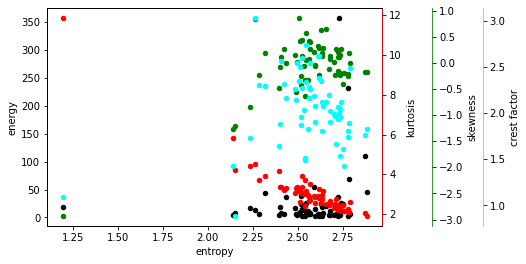

In [460]:
ax_df1 = wpt_df.plot.scatter(x='entropy',y='energy',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='kurtosis',c='red')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.15))
ax_df2.spines['right'].set_edgecolor('green')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='skewness',c='green')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.3))
ax_df2.spines['right'].set_edgecolor('cyan')
wpt_df.plot.scatter(ax=ax_df2, x='entropy',y='crest factor',c='cyan')

<AxesSubplot:xlabel='kurtosis', ylabel='crest factor'>

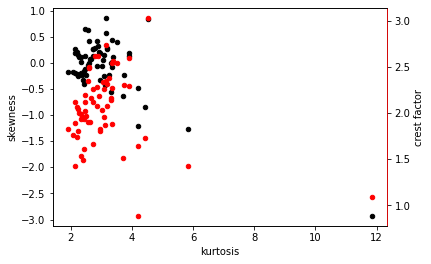

In [461]:
ax_df1 = wpt_df.plot.scatter(x='kurtosis',y='skewness',c='black')

ax_df2 = ax_df1.twinx()
ax_df2.spines['right'].set_position(('axes', 1.0))
ax_df2.spines['right'].set_edgecolor('red')
wpt_df.plot.scatter(ax=ax_df2, x='kurtosis',y='crest factor',c='red')

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [462]:
# tr_ob.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_ob, max(t_plot))

<AxesSubplot:>

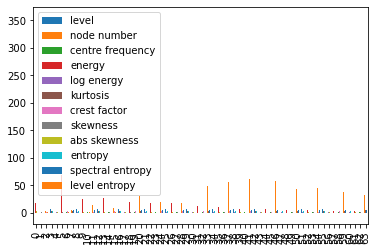

In [463]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [464]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)


In [517]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = [
    "crest factor", 
    "log energy", 
    # "kurtosis",
    "level entropy",
    "spectral entropy"
]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {"init":"k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"elkan",
    }

kmeans = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[ 0.38399592 -0.72310585 -0.42000246  0.42047018]
 [-0.45563708  3.06117153  4.93462568 -3.83285932]
 [-0.43373526  0.65940199  0.15752972 -0.23679526]]
5


In [518]:
data_train_predict

array([2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [519]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [34  2 28]
cluster IDs: [0 1 2]


In [520]:
fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data')

clustering done in 0.02 ± 0.00 s 
Homogeneity: 0.859 ± 0.132
Completeness: 0.859 ± 0.132
V-measure: 0.859 ± 0.132
Adjusted Rand-Index: 0.875 ± 0.135
Silhouette Coefficient: 0.316 ± 0.006


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [521]:
# apply PCA to training data
pca = PCA(n_components=3)#data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters,**kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)

In [522]:
kmeans_pca.cluster_centers_

array([[-0.96466009, -0.58708667, -0.16983312],
       [ 0.3920725 ,  0.52155604,  0.16891278],
       [ 6.84000878, -0.64723929, -0.49385358]])

<AxesSubplot:xlabel='principal component 1', ylabel='principal component 3'>

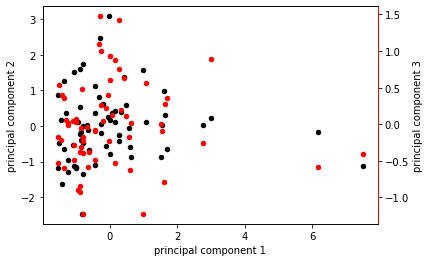

In [523]:
PC_df = pd.DataFrame(data = pca.transform(data_train_normalised)
             , columns = ['principal component 1', 'principal component 2', 'principal component 3'])

ax_pca_df1 = PC_df.plot.scatter(x='principal component 1',y='principal component 2', c='black')

ax_pca_df2 = ax_pca_df1.twinx()
ax_pca_df2.spines['right'].set_position(('axes', 1.0))
ax_pca_df2.spines['right'].set_edgecolor('red')
PC_df.plot.scatter(ax=ax_pca_df2, x='principal component 1',y='principal component 3', c='red')


### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

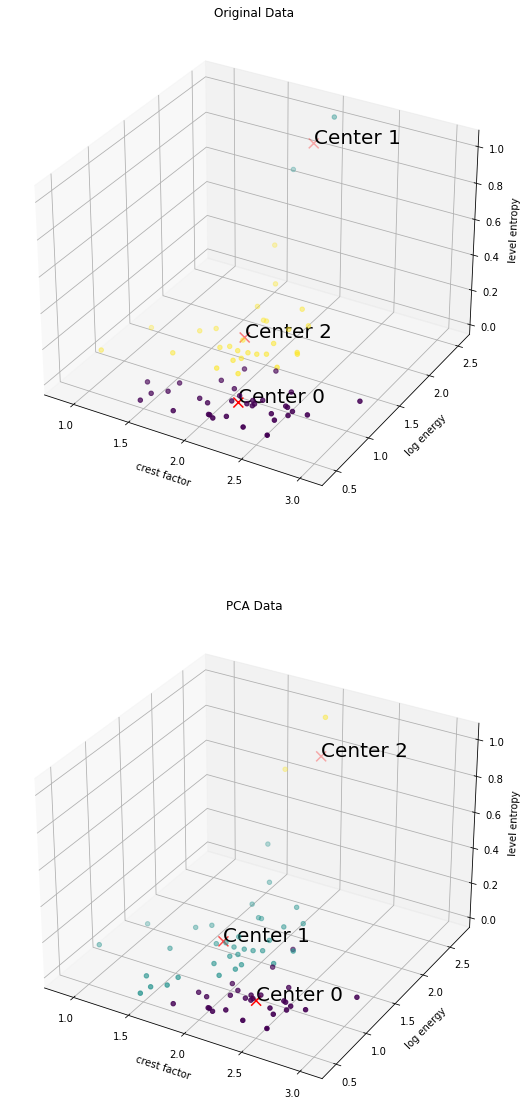

In [524]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = labels
        color_map_labels = data_train_predict 
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = data_train_predict_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    # Annotate cluster centers with their positions
    for j, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {j}', color='black', fontsize=20)

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

Reconstructed nodes by group:


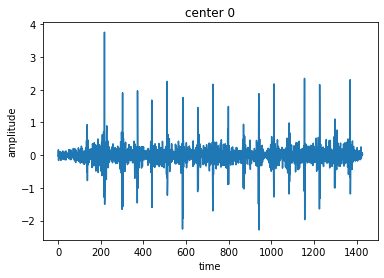

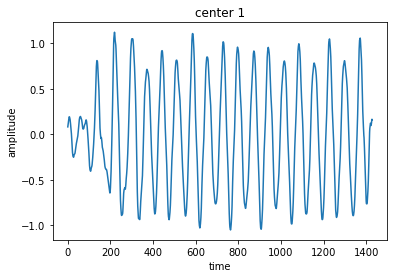

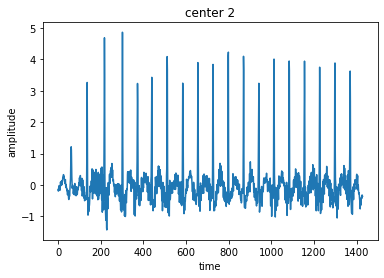

In [525]:
plot.plot_reconstructions_by_group(tr_ob, labels, no_clusters, order="freq")

In [526]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["level entropy"] > THR_Factor * np.max(data_train["level entropy"])
]
harmonics_data = harmonics_data.sort_values(by="level entropy", ascending=False)

In [527]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["crest factor"] > THR_Factor * np.max(data_train["crest factor"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

KeyError: 'kurtosis'

In [ ]:
print(len(harmonics_data["energy"]))
harmonics_data["frequency range"].values.tolist()

15


[('1.25e-1', '1.406e-1'),
 ('9.375e-2', '1.094e-1'),
 ('1.719e-1', '1.875e-1'),
 ('1.562e-1', '1.719e-1'),
 ('2.344e-1', '2.5e-1'),
 ('1.094e-1', '1.25e-1'),
 ('2.188e-1', '2.344e-1'),
 ('1.875e-1', '2.031e-1'),
 ('1.406e-1', '1.562e-1'),
 ('1.562e-2', '3.125e-2'),
 ('3.125e-2', '4.688e-2'),
 ('2.031e-1', '2.188e-1'),
 ('7.812e-2', '9.375e-2'),
 ('4.688e-2', '6.25e-2'),
 ('6.25e-2', '7.812e-2')]

<AxesSubplot:>

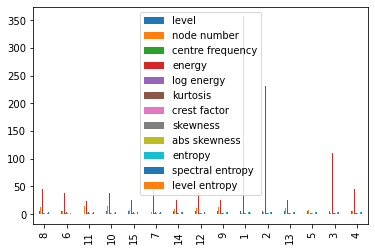

In [ ]:
harmonics_data.plot.bar()

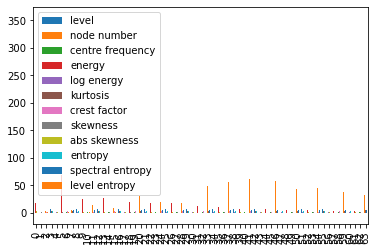

In [ ]:
transient_data.plot.bar()
plt.show()